In [3]:
import pandas as pd

# Define the file path
file_path = "data/data-19403652.csv"

# 1. Select only the necessary columns to save memory
usecols = ["REPORTER", "PARTNER", "PRODUCT", "FLOW", "PERIOD", "INDICATORS", "INDICATOR_VALUE"]

# 2. Optimize data types to speed up loading and reduce RAM usage
dtypes = {
    "REPORTER": "category",
    "PARTNER": "category",
    "PRODUCT": "str",
    "FLOW": "int8",
    "PERIOD": "int32",
    "INDICATORS": "category",
    "INDICATOR_VALUE": "float64",
}


df_raw = pd.read_csv(file_path, usecols=usecols, dtype=dtypes)
print(f"Done! Total rows loaded: {len(df_raw):,}")

# 3. Filter for exports only (FLOW == 2) and drop the FLOW column
df_exp = df_raw[df_raw["FLOW"] == 2].drop(columns=["FLOW"]).copy()
print(f"Rows after filtering for exports: {len(df_exp):,}")

# 4. Pivot the dataset from long to wide format (separating VALUE_EUR and QUANTITY_KG)
df_wide = df_exp.pivot_table(
    index=["REPORTER", "PARTNER", "PRODUCT", "PERIOD"],
    columns="INDICATORS",
    values="INDICATOR_VALUE",
    observed=True
).reset_index()

# Remove the column index name to keep the dataframe clean
df_wide.columns.name = None

print(f"Rows after pivoting (final wide format): {len(df_wide):,}")
df_wide.head()

Done! Total rows loaded: 2,093,424
Rows after filtering for exports: 1,207,718
Rows after pivoting (final wide format): 603,859


,REPORTER,PARTNER,PRODUCT,PERIOD,QUANTITY_KG,VALUE_EUR
0,AT,AE,010121,201903,500.0,11628.0
1,AT,AE,481910,201901,6.0,58.0
2,AT,AE,481910,201902,0.0,28.0
3,AT,AE,481910,201903,0.0,10.0
4,AT,AE,481910,201904,3.0,96.0


In [4]:
import numpy as np

# 1. Extract time variables from the PERIOD column (e.g., 201908 -> Year: 2019, Month: 8)
df_wide["year"] = df_wide["PERIOD"] // 100
df_wide["month"] = df_wide["PERIOD"] % 100

# Create a proper datetime object for time series plotting
df_wide["date"] = pd.to_datetime(df_wide["PERIOD"].astype(str), format="%Y%m")
df_wide.head()

,REPORTER,PARTNER,PRODUCT,PERIOD,QUANTITY_KG,VALUE_EUR,year,month,date
0,AT,AE,010121,201903,500.0,11628.0,2019,3,2019-03-01
1,AT,AE,481910,201901,6.0,58.0,2019,1,2019-01-01
2,AT,AE,481910,201902,0.0,28.0,2019,2,2019-02-01
3,AT,AE,481910,201903,0.0,10.0,2019,3,2019-03-01
4,AT,AE,481910,201904,3.0,96.0,2019,4,2019-04-01


In [ ]:
import pandas as pd
# 1. Zero-Flow Panel Balancing
# Create Arrays 
reporters = df_wide["REPORTER"].unique()
partners = df_wide["PARTNER"].unique()
products = df_wide["PRODUCT"].unique()
periods = df_wide["PERIOD"].unique()

# Cartesian Product erstellen (MultiIndex mit allen theoretisch möglichen Handelsflüssen)
all_combinations = pd.MultiIndex.from_product(
    [reporters, partners, products, periods],
    names=["REPORTER", "PARTNER", "PRODUCT", "PERIOD"]
)

# Filing missing 0 
df_balanced = df_wide.set_index(["REPORTER", "PARTNER", "PRODUCT", "PERIOD"]) \
                     .reindex(all_combinations, fill_value=0) \
                     .reset_index()

print(f"Rows after Zero-Balancing: {len(df_balanced):,}")

# 2. Unit Values calculated (price per kg)
# 
# (HINWEIS: Bitte 'VALUE_EUR' und 'QUANTITY_KG' durch die echten Spaltennamen aus deinem Pivot ersetzen)
df_balanced["UNIT_VALUE"] = df_balanced["VALUE_EUR"] / df_balanced["QUANTITY_KG"].replace(0, np.nan)

# 3. Treatment- und Placebo-Güter markieren

treatment_codes = ["854231", "854232", "854233", "854239"] # Tier 1 integrated circuits[cite: 1]
placebo_codes = ["940360"] # Wooden furniture als Placebo[cite: 1]

# Dummy-Variablen für die DDD-Regression vorbereiten
df_balanced["is_dual_use"] = np.where(df_balanced["PRODUCT"].isin(treatment_codes), 1, 0)
df_balanced["is_placebo"] = np.where(df_balanced["PRODUCT"].isin(placebo_codes), 1, 0)

# Zeitvariablen für den gebalancten Datensatz neu setzen
df_balanced["year"] = df_balanced["PERIOD"] // 100
df_balanced["month"] = df_balanced["PERIOD"] % 100
df_balanced["date"] = pd.to_datetime(df_balanced["PERIOD"].astype(str), format="%Y%m")

df_balanced.head()

Rows after Zero-Balancing: 2,593,296


,REPORTER,PARTNER,PRODUCT,PERIOD,QUANTITY_KG,VALUE_EUR,year,month,date,UNIT_VALUE,is_dual_use,is_placebo
0,AT,AE,010121,201903,500.0,11628.0,2019,3,2019-03-01,23.256,0,0
1,AT,AE,010121,201901,0.0,0.0,2019,1,2019-01-01,NaN,0,0
2,AT,AE,010121,201902,0.0,0.0,2019,2,2019-02-01,NaN,0,0
3,AT,AE,010121,201904,0.0,0.0,2019,4,2019-04-01,NaN,0,0
4,AT,AE,010121,201905,0.0,0.0,2019,5,2019-05-01,NaN,0,0


In [11]:

# 3. Save the finalized dataset as a highly compressed Parquet file
df_wide.to_parquet("data/exports_clean.parquet", index=False)

print("Data preparation complete and saved to Parquet!")
print(f"Time period covered: {df_wide['date'].min().strftime('%Y-%m')} to {df_wide['date'].max().strftime('%Y-%m')}")
df_wide.head()

Data preparation complete and saved to Parquet!
Time period covered: 2019-01 to 2026-08


,REPORTER,PARTNER,PRODUCT,PERIOD,QUANTITY_KG,VALUE_EUR,year,month,date
0,AT,AE,010121,201903,500.0,11628.0,2019,3,2019-03-01
1,AT,AE,481910,201901,6.0,58.0,2019,1,2019-01-01
2,AT,AE,481910,201902,0.0,28.0,2019,2,2019-02-01
3,AT,AE,481910,201903,0.0,10.0,2019,3,2019-03-01
4,AT,AE,481910,201904,3.0,96.0,2019,4,2019-04-01


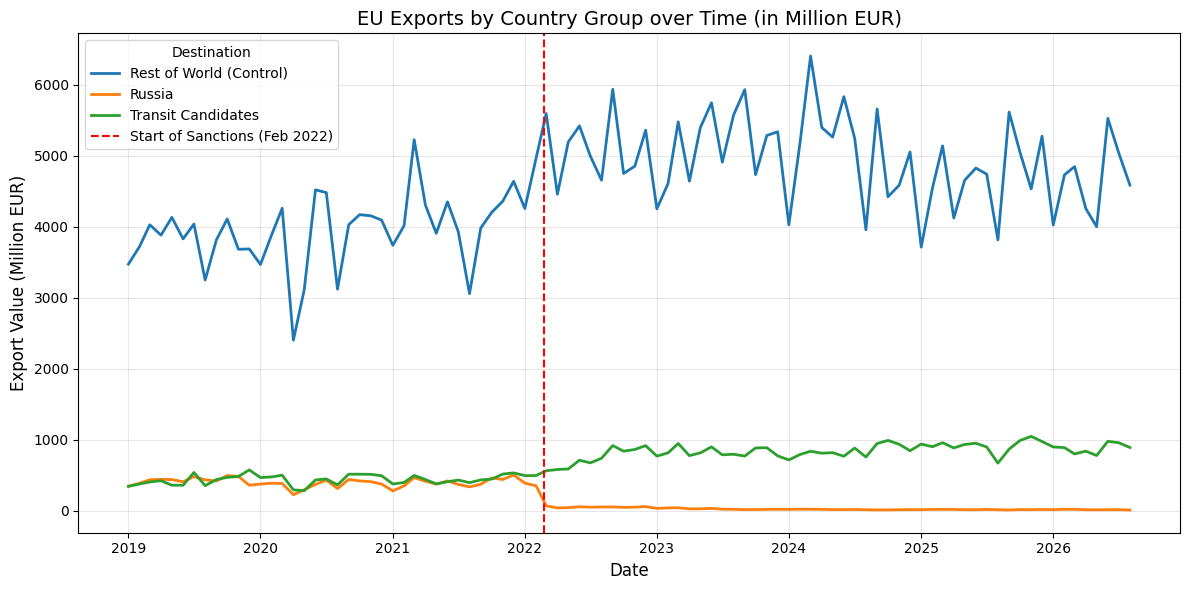

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the fast parquet file
df = pd.read_parquet("data/exports_clean.parquet")

# 2. Define our country groups for the plot
# RU = Russia. We also check typical transit candidates (adjust these to your specific list if needed)
transit_candidates = ["AM", "KZ", "KG", "GE", "AE", "TR", "UZ"]

# Create a new column 'country_group'
df["country_group"] = np.where(
    df["PARTNER"] == "RU", "Russia",
    np.where(df["PARTNER"].isin(transit_candidates), "Transit Candidates", "Rest of World (Control)")
)

# 3. Aggregate total export value per month and group
# We divide by 1,000,000 to show the y-axis in Millions of Euros
monthly_exports = df.groupby(["date", "country_group"], as_index=False)["VALUE_EUR"].sum()
monthly_exports["VALUE_MIO_EUR"] = monthly_exports["VALUE_EUR"] / 1e6

# 4. Plot the data
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_exports, x="date", y="VALUE_MIO_EUR", hue="country_group", linewidth=2)

# Add a vertical red line for the start of the war / major sanctions (Feb 2022)
plt.axvline(pd.to_datetime("2022-02-24"), color="red", linestyle="--", label="Start of Sanctions (Feb 2022)")

plt.title("EU Exports by Country Group over Time (in Million EUR)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Export Value (Million EUR)", fontsize=12)
plt.legend(title="Destination")
plt.grid(alpha=0.3)
plt.tight_layout()

# Show the plot
plt.show()

In [ ]:
import pandas as pd

df = pd.read_parquet("data/exports_clean.parquet")

# 1. Filtern auf reinrassige Zuchtpferde (HS-Code 010121)
hs_code_horses = "010121"
df_horses = df[df["PRODUCT"] == hs_code_horses].copy()

# 2. Kurzer Check, wie viele Daten übrig bleiben
print(f"Beobachtungen für Luxuspferde ({hs_code_horses}): {len(df_horses)} Zeilen")
print("Anzahl der EU-Länder, die diese Pferde exportieren:", df_horses["REPORTER"].nunique())
print("Anzahl der Zielländer:", df_horses["PARTNER"].nunique())

# Zeige die ersten 5 Zeilen sortiert nach Datum
df_horses = df_horses.sort_values(by=["date", "REPORTER", "PARTNER"]).reset_index(drop=True)
df_horses.head()

Beobachtungen für Luxuspferde (010121): 1034 Zeilen
Anzahl der EU-Länder, die diese Pferde exportieren: 20
Anzahl der Zielländer: 18


,REPORTER,PARTNER,PRODUCT,PERIOD,QUANTITY_KG,VALUE_EUR,year,month,date
0,DE,AE,010121,201901,500.0,575500.0,2019,1,2019-01-01
1,DE,IN,010121,201901,3000.0,156350.0,2019,1,2019-01-01
2,EE,RU,010121,201901,1000.0,8600.0,2019,1,2019-01-01
3,FR,AE,010121,201901,900.0,29000.0,2019,1,2019-01-01
4,FR,CN,010121,201901,6600.0,132320.0,2019,1,2019-01-01


In [14]:
import pandas as pd
import numpy as np

# 1. Alle einzigartigen Ausprägungen extrahieren
reporters = df_horses["REPORTER"].unique()
partners = df_horses["PARTNER"].unique()
dates = df_horses["date"].unique()

# 2. Ein vollständiges Raster (MultiIndex) aller möglichen Kombinationen erstellen
full_index = pd.MultiIndex.from_product(
    [reporters, partners, dates],
    names=["REPORTER", "PARTNER", "date"]
)

# 3. Den aktuellen Datensatz auf dieses vollständige Raster anwenden (Reindexing)
df_horses_squared = (
    df_horses.set_index(["REPORTER", "PARTNER", "date"])
    .reindex(full_index)
    .reset_index()
)

# 4. Den Produktcode für die neu geschaffenen Zeilen wieder eintragen
df_horses_squared["PRODUCT"] = hs_code_horses

# 5. Fehlende Werte (implizite Nullen) bei Wert und Menge mit echten Nullen auffüllen
df_horses_squared["VALUE_EUR"] = df_horses_squared["VALUE_EUR"].fillna(0)
df_horses_squared["QUANTITY_KG"] = df_horses_squared["QUANTITY_KG"].fillna(0)

# 6. Unit Value neu berechnen (wo Menge 0 ist, bleibt es NaN, da durch 0 teilen nicht geht)
df_horses_squared["unit_value"] = np.where(
    (df_horses_squared["QUANTITY_KG"] > 0) & (df_horses_squared["VALUE_EUR"] > 0),
    df_horses_squared["VALUE_EUR"] / df_horses_squared["QUANTITY_KG"],
    np.nan
)

# Sortieren für eine saubere Ansicht
df_horses_squared = df_horses_squared.sort_values(["REPORTER", "PARTNER", "date"]).reset_index(drop=True)

print(f"Zeilen vorher (nur tatsächliche Exporte): {len(df_horses):,}")
print(f"Zeilen nachher (komplettes, quadriertes Panel): {len(df_horses_squared):,}")
df_horses_squared.head()

Zeilen vorher (nur tatsächliche Exporte): 1,034
Zeilen nachher (komplettes, quadriertes Panel): 33,120


,REPORTER,PARTNER,date,PRODUCT,PERIOD,QUANTITY_KG,VALUE_EUR,year,month,unit_value
0,AT,AE,2019-01-01,010121,NaN,0.0,0.0,NaN,NaN,NaN
1,AT,AE,2019-02-01,010121,NaN,0.0,0.0,NaN,NaN,NaN
2,AT,AE,2019-03-01,010121,201903.0,500.0,11628.0,2019.0,3.0,23.256
3,AT,AE,2019-04-01,010121,NaN,0.0,0.0,NaN,NaN,NaN
4,AT,AE,2019-05-01,010121,NaN,0.0,0.0,NaN,NaN,NaN


Destination countries (PARTNER): ['AE', 'AM', 'AU', 'BR', 'CL', 'CN', 'GE', 'IL', 'IN', 'IR', 'KG', 'KR', 'KZ', 'MX', 'RU', 'TR', 'UZ', 'ZA']


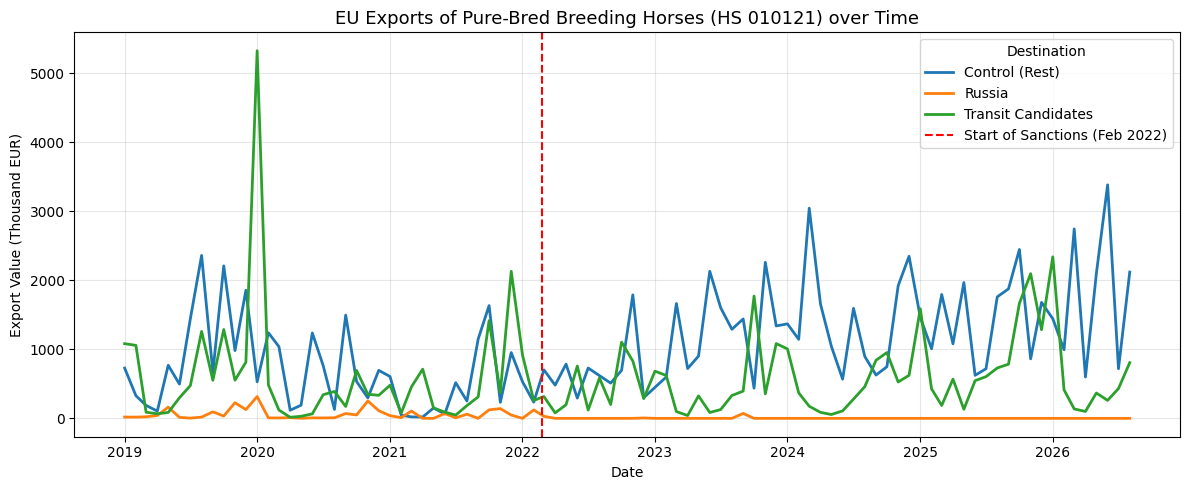

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Print the exact 18 destination countries in this subset
print("Destination countries (PARTNER):", sorted(df_horses_squared["PARTNER"].unique()))

# 2. Assign country groups
transit_candidates = ["AM", "KZ", "KG", "GE", "AE", "TR", "UZ"]

df_horses_squared["country_group"] = np.where(
    df_horses_squared["PARTNER"] == "RU", "Russia",
    np.where(df_horses_squared["PARTNER"].isin(transit_candidates), "Transit Candidates", "Control (Rest)")
)

# 3. Aggregate monthly export value (in Thousand EUR for better readability)
monthly_horses = (
    df_horses_squared.groupby(["date", "country_group"], as_index=False)["VALUE_EUR"]
    .sum()
)
monthly_horses["VALUE_K_EUR"] = monthly_horses["VALUE_EUR"] / 1e3

# 4. Plot the time series
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_horses, x="date", y="VALUE_K_EUR", hue="country_group", linewidth=2)
plt.axvline(pd.to_datetime("2022-02-24"), color="red", linestyle="--", label="Start of Sanctions (Feb 2022)")

plt.title("EU Exports of Pure-Bred Breeding Horses (HS 010121) over Time", fontsize=13)
plt.xlabel("Date")
plt.ylabel("Export Value (Thousand EUR)")
plt.legend(title="Destination")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# 1. Remove UAE (AE) completely from both transit and control groups
df_no_ae = df_horses_squared[df_horses_squared["PARTNER"] != "AE"].copy()

# 2. Compare total horse exports (in EUR) per transit country before vs. after sanctions
transit_no_ae = ["AM", "KZ", "KG", "GE", "TR", "UZ"]
df_no_ae["period_group"] = np.where(
    df_no_ae["date"] >= "2022-03-01", "Post (from Mar 2022)", "Pre (until Feb 2022)"
)

transit_breakdown = (
    df_no_ae[df_no_ae["PARTNER"].isin(transit_no_ae)]
    .groupby(["PARTNER", "period_group"], observed=True)["VALUE_EUR"]
    .sum()
    .unstack(fill_value=0)
)

print("Total horse exports (in EUR) to individual transit countries:")
print(transit_breakdown)

Total horse exports (in EUR) to individual transit countries:
period_group  Post (from Mar 2022)  Pre (until Feb 2022)
PARTNER                                                 
AM                        164637.0                   0.0
GE                          4004.0              129618.0
KG                       3776474.0             1201174.0
KZ                        201794.0              368989.0
TR                       6540912.0             4231602.0
UZ                        227164.0             2336620.0


In [20]:
import numpy as np
import pandas as pd
import pyfixest as pf

# 1. Exclude both UAE (AE) and direct target Russia (RU) from the sample
# Keeping RU in the control group would artificially downward-bias the control trend
df_did = df_horses_squared[~df_horses_squared["PARTNER"].isin(["AE", "RU"])].copy()

# 2. Define Treatment (Transit Countries) and Post-Sanctions Period
transit_no_ae = ["AM", "KZ", "KG", "GE", "TR", "UZ"]
df_did["treat"] = df_did["PARTNER"].isin(transit_no_ae).astype(int)
df_did["post"] = (df_did["date"] >= "2022-03-01").astype(int)

# Interaction term (the actual DiD estimator)
df_did["did"] = df_did["treat"] * df_did["post"]

# 3. Create country-pair identifier for Pair Fixed Effects and log(value + 1)
df_did["pair_id"] = df_did["REPORTER"].astype(str) + "_" + df_did["PARTNER"].astype(str)
df_did["log_value"] = np.log1p(df_did["VALUE_EUR"])

# 4. Estimate Two-Way Fixed Effects (TWFE) OLS and PPML models
# Fixed Effects: Country-pair (pair_id) + Month-Year (date)
# Standard errors clustered at the destination country level (PARTNER)
est_ols = pf.feols(
    "log_value ~ did | pair_id + date",
    data=df_did,
    vcov={"CRV1": "PARTNER"}
)

est_ppml = pf.fepois(
    "VALUE_EUR ~ did | pair_id + date",
    data=df_did,
    vcov={"CRV1": "PARTNER"}
)

# 5. Display clean regression table comparing both models
print("Difference-in-Differences Results for Pure-Bred Horses (HS 010121):")
pf.etable([est_ols, est_ppml])

Difference-in-Differences Results for Pure-Bred Horses (HS 010121):


c:\Users\meloh\Projects\Research_2026_UniBonn\.venv\lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 22172 observations removed because of separation.
  warnings.warn(


GT(_tbl_data=  __index_level_0__ __index_level_1__                    0  \
0              coef               did  -0.082 <br> (0.107)   
1                fe              date                    -   
2                fe           pair_id                    -   
3             stats      Observations               29,440   
4             stats                R²                0.382   

                     1  
0  -0.683 <br> (0.467)  
1                    -  
2                    -  
3                7,268  
4                    -  , _body=<great_tables._gt_data.Body object at 0x0000021D9ECEE500>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x0000021D9ED41870>, _spanners=Spanners([SpannerInfo(spanner_id='log_value', spanner_level=1, spanner_label=Html(text='log_value'), spanner_units=None, spanner_pattern=None, vars=['0'], built=None), SpannerInfo(spanner_id='VALUE_EUR', spanner_level=1, spanner_label=Html(text='VALUE_EUR'), spanner_units=None, spanner_pattern=None, vars=['1'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x0000021D9ED41780>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x0000021D9ED406D0>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x0000021D9ED417B0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x0000021D9ED41EA0>, <great_tables._gt_data.FormatInfo object at 0x0000021D9ED416F0>, <great_tables._gt_data.FormatInfo object at 0x0000021D9ED41CC0>, <great_tables._gt_data.FormatInfo object at 0x0000021D9ED40E20>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='va